In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.utils import resample
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
windows_qc = pd.read_csv("outputs/windows_requested_features2.csv")

In [5]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.utils import resample
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

FEATS = [
    "fix_efficiency","fix_aoi_ratio","gaze_dispersion_total",
    "pupil_mean","pupil_var","saccade_mean_mag","saccade_dir_var",
    "blink_rate","valid_gaze_ratio",
]

def zscore_within_participant_safe(df, feats, pid_col="User ID (file)"):
    out = df.copy()
    for pid, grp in out.groupby(pid_col):
        mu = grp[feats].median(numeric_only=True)
        sd = grp[feats].std(numeric_only=True)
        # avoid divide-by-zero → set zeros to 1 so (x-μ)/1 = x-μ
        sd = sd.replace(0, 1.0)
        out.loc[grp.index, feats] = (grp[feats] - mu) / sd
    return out

def pca_one_type(windows_qc, anim_type, feats=FEATS, balance=True, random_state=0):
    sub = windows_qc[windows_qc["type"].str.upper()==anim_type.upper()].copy()
    if sub.empty:
        print(f"No rows for type {anim_type}")
        return sub, None, None

    # 1) participant-wise safe z-score
    sub = zscore_within_participant_safe(sub, feats)

    # 2) optional balance ON/OFF
    if balance:
        on, off = sub[sub["label"]=="ON"], sub[sub["label"]=="OFF"]
        n = min(len(on), len(off))
        if n == 0:
            print(f"{anim_type}: cannot balance (one class empty). Using all data.")
        else:
            sub = pd.concat([
                resample(on,  replace=False, n_samples=n, random_state=random_state),
                resample(off, replace=False, n_samples=n, random_state=random_state)
            ], axis=0).sample(frac=1, random_state=random_state).reset_index(drop=True)

    # 3) drop features that are entirely NaN in this subset
    good_feats = [f for f in feats if sub[f].notna().any()]
    if not good_feats:
        print(f"{anim_type}: all features NaN after filtering.")
        return sub, None, None

    # 4) impute (median) → scale → PCA
    X = sub[good_feats].replace([np.inf, -np.inf], np.nan)
    imputer = SimpleImputer(strategy="median")
    scaler  = StandardScaler()
    X = imputer.fit_transform(X)
    X = scaler.fit_transform(X)

    pca = PCA(n_components=2, random_state=random_state)
    PCs = pca.fit_transform(X)
    sub["PC1"], sub["PC2"] = PCs[:,0], PCs[:,1]

    # Plot
    sns.scatterplot(data=sub, x="PC1", y="PC2", hue="label", alpha=0.6)
    evr = pca.explained_variance_ratio_
    plt.title(f"PCA (participant-z, imputed) — {anim_type}  |  EVR: {evr[0]:.2f}, {evr[1]:.2f}")
    plt.axhline(0, ls="--", lw=0.5); plt.axvline(0, ls="--", lw=0.5)
    plt.tight_layout(); plt.show()

    # Loadings (contributions)
    load = pd.DataFrame({
        "feature": good_feats,
        "PC1": np.abs(pca.components_[0]),
        "PC2": np.abs(pca.components_[1]),
    }).set_index("feature").sort_index()

    print("Top PC1:\n", load["PC1"].sort_values(ascending=False).head(8))
    print("Top PC2:\n", load["PC2"].sort_values(ascending=False).head(8))

    return sub, pca, load

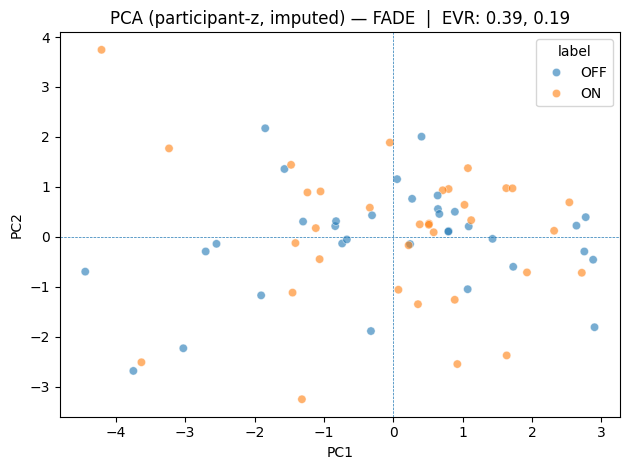

Top PC1:
 feature
valid_gaze_ratio         0.480190
saccade_mean_mag         0.466235
saccade_dir_var          0.420578
gaze_dispersion_total    0.395337
fix_efficiency           0.363956
pupil_var                0.204332
blink_rate               0.170210
pupil_mean               0.125214
Name: PC1, dtype: float64
Top PC2:
 feature
pupil_mean               0.571066
blink_rate               0.546655
pupil_var                0.493720
fix_efficiency           0.282616
saccade_mean_mag         0.149353
saccade_dir_var          0.132060
valid_gaze_ratio         0.107125
gaze_dispersion_total    0.014130
Name: PC2, dtype: float64


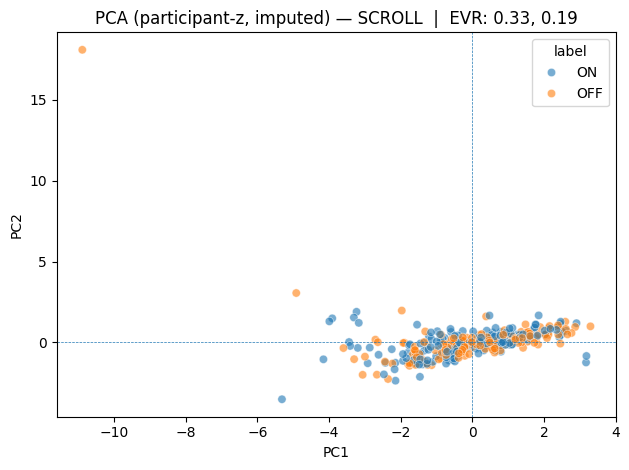

Top PC1:
 feature
valid_gaze_ratio         0.522100
fix_efficiency           0.443381
gaze_dispersion_total    0.437814
saccade_dir_var          0.411765
saccade_mean_mag         0.317131
blink_rate               0.214583
pupil_var                0.146533
pupil_mean               0.038768
Name: PC1, dtype: float64
Top PC2:
 feature
saccade_mean_mag         0.631030
gaze_dispersion_total    0.497740
blink_rate               0.318733
saccade_dir_var          0.317285
fix_efficiency           0.272835
pupil_var                0.203449
pupil_mean               0.147072
valid_gaze_ratio         0.119730
Name: PC2, dtype: float64


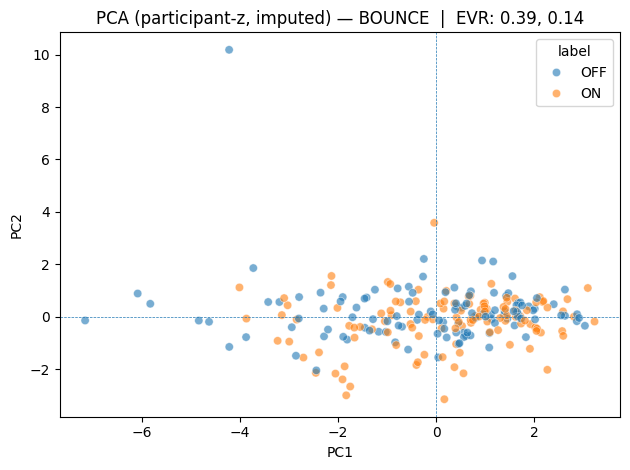

Top PC1:
 feature
valid_gaze_ratio         0.458568
saccade_mean_mag         0.458119
fix_efficiency           0.452724
gaze_dispersion_total    0.420145
saccade_dir_var          0.404628
pupil_var                0.115823
pupil_mean               0.108640
blink_rate               0.096982
Name: PC1, dtype: float64
Top PC2:
 feature
pupil_mean          0.674451
pupil_var           0.605142
blink_rate          0.391654
saccade_dir_var     0.099118
valid_gaze_ratio    0.090876
fix_efficiency      0.070873
fix_aoi_ratio       0.045650
saccade_mean_mag    0.017293
Name: PC2, dtype: float64


In [9]:
for t in ["FADE","SCROLL","BOUNCE"]:
    _sub, _pca, _load = pca_one_type(windows_qc, t)


=== FADE ===  (n=536)  EVR: PC1=0.37, PC2=0.15

Top features driving PC1 (FADE):
valid_gaze_ratio         4.818659e-01
fix_efficiency           4.437343e-01
gaze_dispersion_total    4.305362e-01
saccade_mean_mag         4.213681e-01
saccade_dir_var          4.054003e-01
blink_rate               1.806840e-01
pupil_var                1.046340e-01
pupil_mean               6.944441e-03
fix_aoi_ratio            4.440892e-16
Name: PC1, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


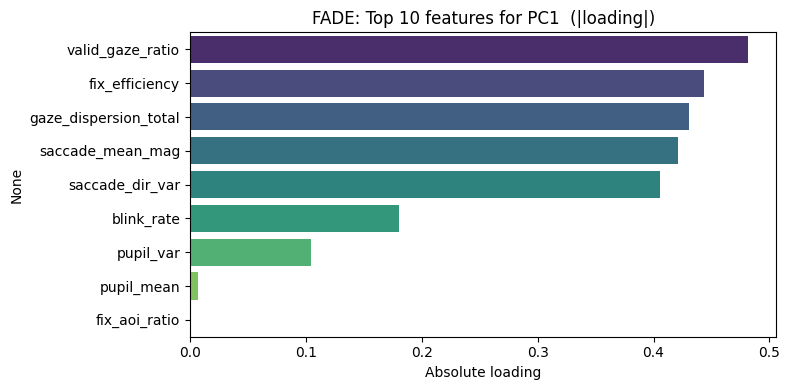


Top features driving PC2 (FADE):
blink_rate               5.263878e-01
saccade_mean_mag         4.753962e-01
gaze_dispersion_total    4.668996e-01
pupil_var                3.022197e-01
saccade_dir_var          2.768188e-01
pupil_mean               2.198720e-01
valid_gaze_ratio         1.846873e-01
fix_efficiency           1.688210e-01
fix_aoi_ratio            2.775558e-16
Name: PC2, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


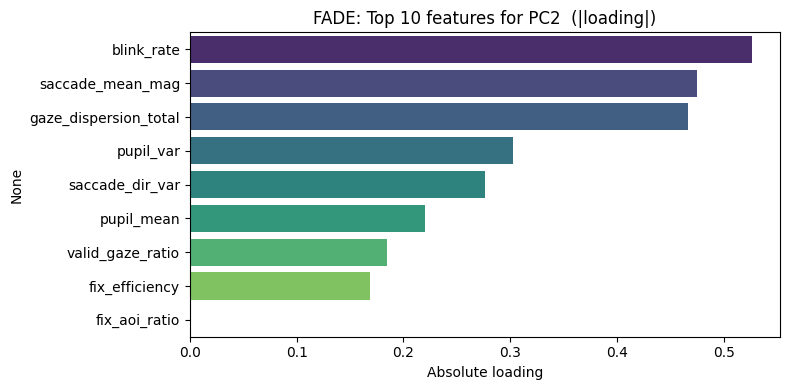


=== SCROLL ===  (n=2594)  EVR: PC1=0.32, PC2=0.18

Top features driving PC1 (SCROLL):
valid_gaze_ratio         5.472221e-01
fix_efficiency           5.122196e-01
saccade_dir_var          4.359824e-01
gaze_dispersion_total    3.925935e-01
blink_rate               2.260481e-01
saccade_mean_mag         1.591514e-01
pupil_var                1.170529e-01
pupil_mean               6.197138e-02
fix_aoi_ratio            1.110223e-16
Name: PC1, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


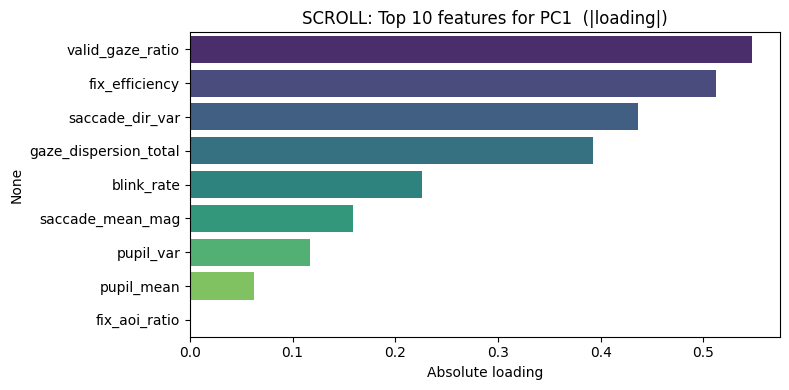


Top features driving PC2 (SCROLL):
pupil_mean               7.073861e-01
pupil_var                6.915008e-01
fix_efficiency           7.844099e-02
blink_rate               7.113806e-02
saccade_dir_var          6.775358e-02
gaze_dispersion_total    6.232140e-02
saccade_mean_mag         3.888534e-02
valid_gaze_ratio         1.521361e-02
fix_aoi_ratio            6.938894e-17
Name: PC2, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


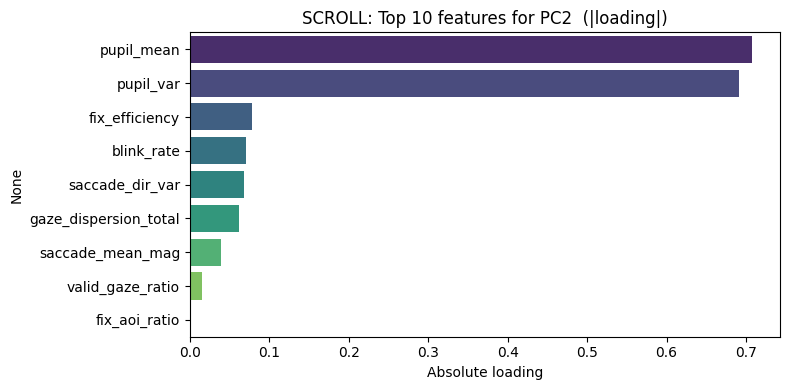


=== BOUNCE ===  (n=651)  EVR: PC1=0.29, PC2=0.13

Top features driving PC1 (BOUNCE):
valid_gaze_ratio         0.535285
fix_efficiency           0.504578
saccade_dir_var          0.468688
gaze_dispersion_total    0.420828
blink_rate               0.150657
pupil_var                0.145098
saccade_mean_mag         0.104082
pupil_mean               0.086538
fix_aoi_ratio            0.005824
Name: PC1, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


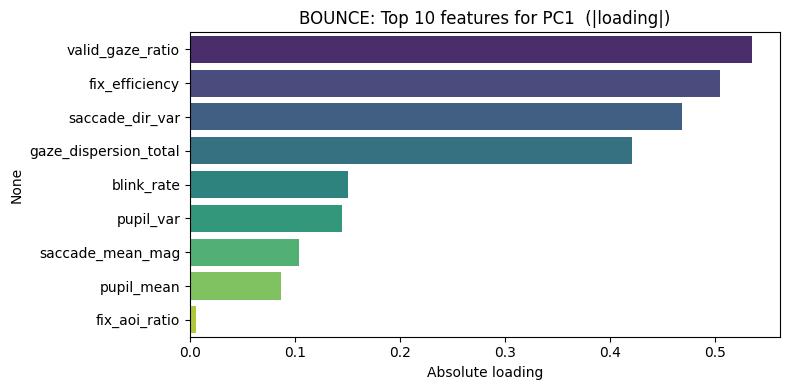


Top features driving PC2 (BOUNCE):
pupil_mean               0.739536
saccade_mean_mag         0.490101
pupil_var                0.401048
fix_aoi_ratio            0.151454
blink_rate               0.139251
valid_gaze_ratio         0.063610
fix_efficiency           0.061849
saccade_dir_var          0.042980
gaze_dispersion_total    0.000849
Name: PC2, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


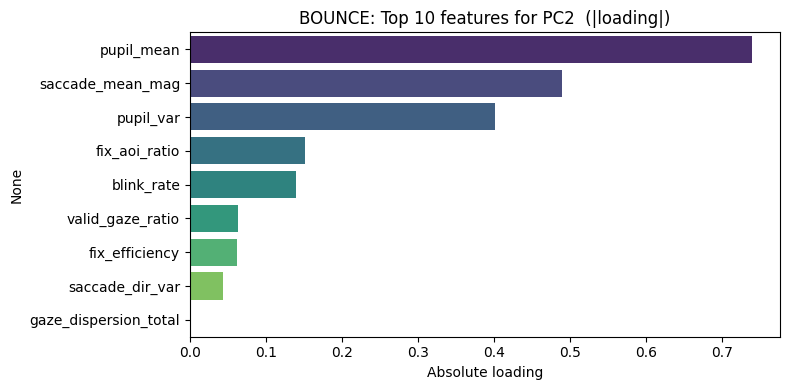


=== UNKNOWN ===  (n=1815)  EVR: PC1=0.29, PC2=0.15

Top features driving PC1 (UNKNOWN):
valid_gaze_ratio         0.504640
fix_efficiency           0.447943
gaze_dispersion_total    0.424327
saccade_dir_var          0.409169
saccade_mean_mag         0.378636
blink_rate               0.211596
pupil_var                0.072309
pupil_mean               0.061560
fix_aoi_ratio            0.007604
Name: PC1, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


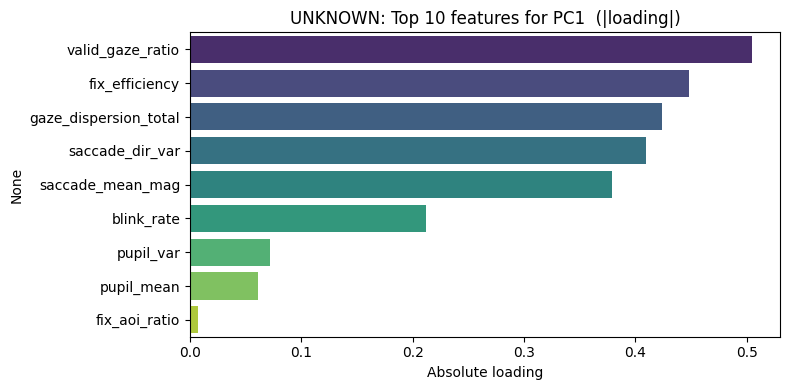


Top features driving PC2 (UNKNOWN):
saccade_mean_mag         0.537884
gaze_dispersion_total    0.494444
blink_rate               0.461108
saccade_dir_var          0.307203
pupil_var                0.234193
valid_gaze_ratio         0.224198
pupil_mean               0.163509
fix_efficiency           0.155756
fix_aoi_ratio            0.055711
Name: PC2, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_1232/3942267004.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top.values, y=top.index, palette="viridis")


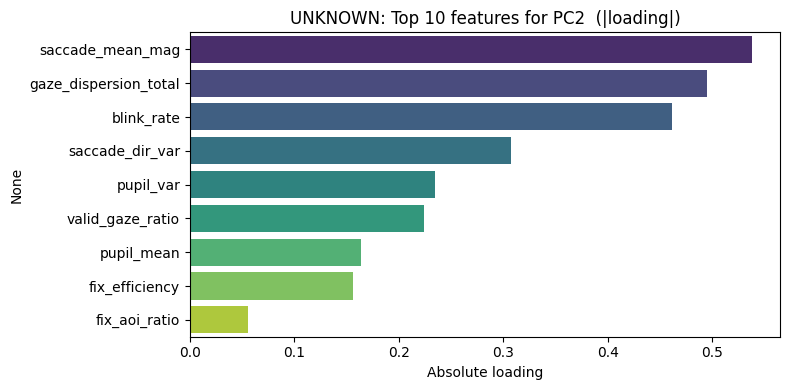

In [10]:
# ---- Config ----
FEATS = [
    "fix_efficiency", "fix_aoi_ratio",
    "gaze_dispersion_total",
    "pupil_mean", "pupil_var",
    "saccade_mean_mag","saccade_dir_var",
    "blink_rate",
    "valid_gaze_ratio",
]

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def pca_loadings_by_type(df, feats=FEATS, types=None, topk=10, random_state=0):
    """
    For each animation type, run PCA (2 PCs) on the given features and
    report/plot the top absolute loadings for PC1 and PC2.
    """
    if types is None:
        types = (
            df["type"].astype(str).str.upper().str.strip()
              .value_counts().index.tolist()
        )

    for t in types:
        sub = df[df["type"].astype(str).str.upper().str.strip() == t].copy()
        if sub.empty:
            print(f"\n[{t}] — no rows, skipping.")
            continue

        # Keep only rows with at least one finite feature value
        Xraw = sub[feats].copy()
        if Xraw.dropna(how="all").empty:
            print(f"\n[{t}] — all-NaN features, skipping.")
            continue

        # Impute + scale
        imp = SimpleImputer(strategy="median")
        scl = StandardScaler()
        X_imp = imp.fit_transform(Xraw)
        X     = scl.fit_transform(X_imp)

        # Fit PCA
        pca = PCA(n_components=2, random_state=random_state)
        PC  = pca.fit_transform(X)
        evr = pca.explained_variance_ratio_

        print(f"\n=== {t} ===  (n={len(sub)})  EVR: PC1={evr[0]:.2f}, PC2={evr[1]:.2f}")

        # Build loadings table
        loadings = pd.DataFrame(
            pca.components_.T,
            columns=[f"PC{i+1}" for i in range(pca.n_components_)],
            index=feats
        )

        # Show & plot top features per PC
        for pc in ["PC1", "PC2"]:
            top = loadings[pc].abs().sort_values(ascending=False).head(topk)
            print(f"\nTop features driving {pc} ({t}):")
            print(top)

            plt.figure(figsize=(8,4))
            sns.barplot(x=top.values, y=top.index, palette="viridis")
            plt.title(f"{t}: Top {topk} features for {pc}  (|loading|)")
            plt.xlabel("Absolute loading")
            plt.tight_layout()
            plt.show()

# ---- Run it ----
# assumes you have windows_qc with the cleaned features + 'type'
pca_loadings_by_type(windows_qc, feats=FEATS, types=["FADE","SCROLL","BOUNCE","UNKNOWN"], topk=10)